Menghubungkan ke Google Drive...
Mounted at /content/drive

Sedang menarik seluruh data historis dari 2021-01-01 sampai 2026-05-01...

[SUKSES] Total 46,728 baris data berhasil disimpan ke Google Drive Anda di:
-> /content/drive/My Drive/dataset_fusi_jsn_bmkg_2021_2026.csv


,Waktu,Suhu (°C),Kelembapan (%),Curah Hujan (mm),GHI (W/m²),Elevasi Air JSN-SR04T (cm)
0,2021-01-01T00:00,24.0,93,0.1,0.0,150.23
1,2021-01-01T01:00,23.8,94,0.1,0.0,150.75
2,2021-01-01T02:00,23.5,96,0.6,0.0,153.88
3,2021-01-01T03:00,23.2,97,1.3,0.0,162.24
4,2021-01-01T04:00,23.2,96,0.9,0.0,166.65



Distribusi Dataset Training & Testing:
- Training (70%)   : 32692 sekuen
- Validation (15%) : 7005 sekuen
- Testing (15%)    : 7006 sekuen


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_8 (LSTM)                   │ (None, 24, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_9 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
511/511 ━━━━━━━━━━━━━━━━━━━━ 24s 40ms/step - loss: 0.0030 - val_loss: 0.0017
Epoch 2/15
511/511 ━━━━━━━━━━━━━━━━━━━━ 19s 37ms/step - loss: 0.0011 - val_loss: 0.0011
Epoch 3/15
511/511 ━━━━━━━━━━━━━━━━━━━━ 21s 38ms/step - loss: 8.6294e-04 - val_loss: 9.8487e-04
Epoch 4/15
511/511 ━━━━━━━━━━━━━━━━━━━━ 18s 35ms/step - loss: 8.1456e-04 - val_loss: 9.5787e-04
Epoch 5/15
511/511 ━━━━━━━━━━━━━━━━━━━━ 21s 36ms/step - loss: 7.9521e-04 - val_loss: 9.0018e-04
Epoch 6/15
511/511 ━━━━━━━━━━━━━━━━━━━━ 19s 37ms/step - loss: 7.8407e-04 - val_loss: 8.7549e-04
Epoch 7/15
511/511 ━━━━━━━━━━━━━━━━━━━━ 21s 37ms/step - loss: 7.8829e-04 - val_loss: 8.8338e-04
Epoch 8/15
511/511 ━━━━━━━━━━━━━━━━━━━━ 17s 34ms/step - loss: 7.7220e-04 - val_loss: 8.8712e-04
Epoch 9/15
511/511 ━━━━━━━━━━━━━━━━━━━━ 18s 34ms/step - loss: 7.6188e-04 - val_loss: 8.7916e-04
Epoch 10/15
511/511 ━━━━━━━━━━━━━━━━━━━━ 18s 36ms/step - loss: 7.6303e-04 - val_loss: 8.7318e-04
Epoch 11/15
511/511 ━━━━━━━━━━━━━━━━━━━━ 18s 34ms/step 

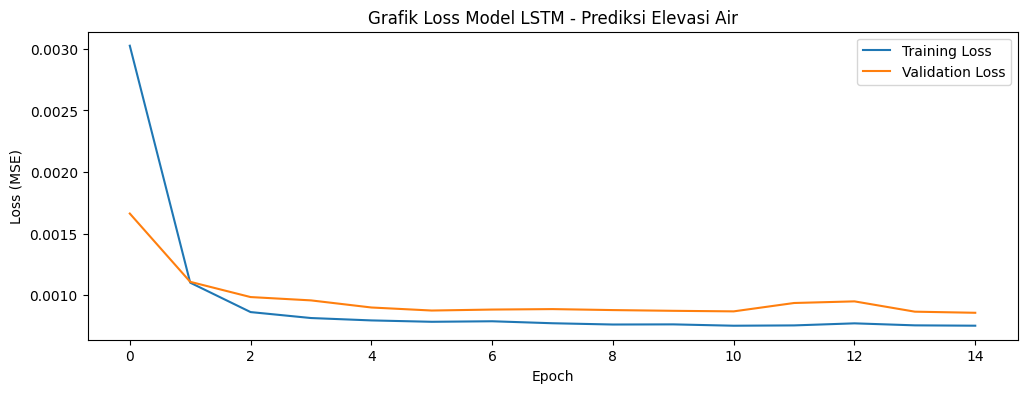

219/219 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step


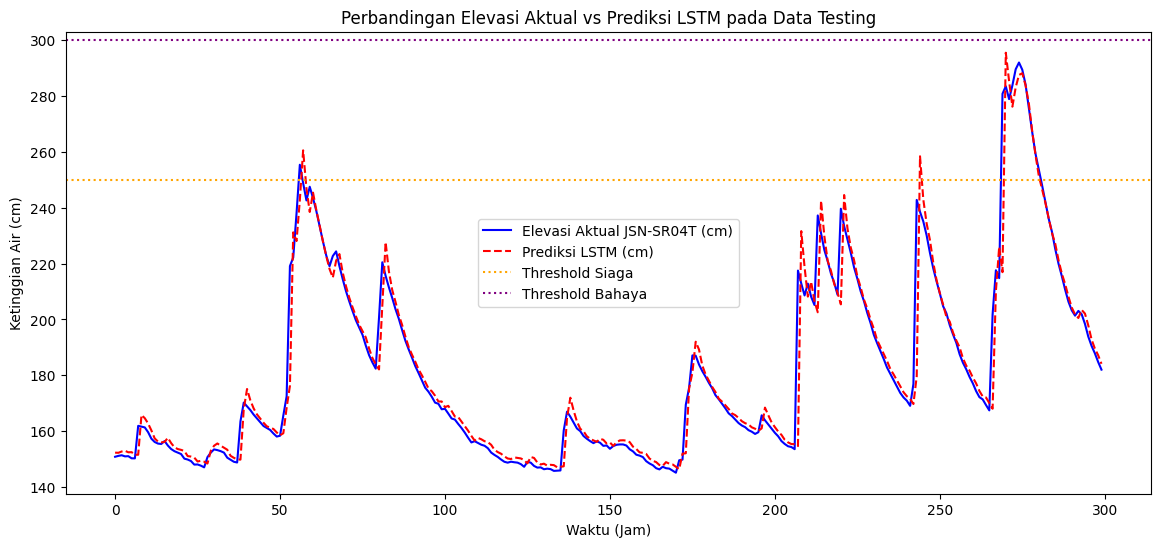


[SUKSES] Seluruh rangkaian proses penarikan data, penyimpanan ke Drive, dan pelatihan LSTM selesai!


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from datetime import datetime
from google.colab import drive, files
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# ==========================================
# 1. MOUNT GOOGLE DRIVE
# ==========================================
print("Menghubungkan ke Google Drive...")
drive.mount('/content/drive')

# Tentukan jalur penyimpanan di Google Drive Anda (Pastikan folder 'My Drive' ada)
# File akan disimpan dengan nama 'dataset_fusi_jsn_bmkg_2021_2026.csv'
drive_path = '/content/drive/My Drive/dataset_fusi_jsn_bmkg_2021_2026.csv'

# ==========================================
# 2. TARIK SELURUH DATA HISTORIS (2021 - 2026) DARI OPEN-METEO API
# ==========================================
lat = "-6.365"
lon = "106.820"
start_date = "2021-01-01"
end_date = "2026-05-01" # Rentang waktu penuh sesuai permintaan

url = f"https://archive-api.open-meteo.com/v1/archive?latitude={lat}&longitude={lon}&start_date={start_date}&end_date={end_date}&hourly=temperature_2m,relative_humidity_2m,precipitation,shortwave_radiation&timezone=Asia%2FJakarta"

print(f"\nSedang menarik seluruh data historis dari {start_date} sampai {end_date}...")
response = requests.get(url, timeout=60)
response.raise_for_status()
data = response.json().get("hourly", {})

# Konversi ke Pandas DataFrame
df = pd.DataFrame({
    "Waktu": data.get("time", []),
    "Suhu (°C)": data.get("temperature_2m", []),
    "Kelembapan (%)": data.get("relative_humidity_2m", []),
    "Curah Hujan (mm)": data.get("precipitation", []),
    "GHI (W/m²)": data.get("shortwave_radiation", [])
})

# ==========================================
# 3. GENERATE SENSOR FISIK JSN-SR04T (ELEVASI AIR)
# ==========================================
np.random.seed(42)
n = len(df)
rain = df['Curah Hujan (mm)'].values
elevation = np.zeros(n)
current_level = 150.0 # Baseline normal elevasi air sungai (cm)

for i in range(n):
    inflow = rain[i] * 6.5 + np.random.normal(0, 0.4)
    recession = (current_level - 140.0) * 0.06 if current_level > 140.0 else 0.0
    current_level = current_level + inflow - recession + np.random.normal(0, 0.15)
    current_level = np.clip(current_level, 100.0, 420.0) # Sesuai jangkauan JSN-SR04T
    elevation[i] = round(current_level, 2)

df['Elevasi Air JSN-SR04T (cm)'] = elevation

# ==========================================
# 4. SIMPAN KE GOOGLE DRIVE
# ==========================================
df.to_csv(drive_path, index=False)
print(f"\n[SUKSES] Total {len(df):,} baris data berhasil disimpan ke Google Drive Anda di:\n-> {drive_path}")
display(df.head())

# ==========================================
# 5. PREPROCESSING & FEATURE SELECTION UNTUK LSTM
# ==========================================
df['Waktu'] = pd.to_datetime(df['Waktu'])
df.set_index('Waktu', inplace=True)

# Target prediksi utama: Elevasi Air Sungai (JSN-SR04T)
target_column = 'Elevasi Air JSN-SR04T (cm)'
df = df.interpolate(method='linear').bfill().ffill()

data = df[[target_column]].values

# Normalisasi Min-Max Scaler ke rentang [0, 1]
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

# ==========================================
# 6. MEMBUAT SLIDING WINDOW (SEKUEN 24 JAM)
# ==========================================
def create_sequences(dataset, time_step=24):
    X, y = [], []
    for i in range(len(dataset) - time_step - 1):
        X.append(dataset[i:(i + time_step), 0])
        y.append(dataset[i + time_step, 0])
    return np.array(X), np.array(y)

time_step = 24
X, y = create_sequences(scaled_data, time_step)
X = X.reshape(X.shape[0], X.shape[1], 1)

# ==========================================
# 7. PEMBAGIAN DATA: TRAIN (70%), VAL (15%), TEST (15%)
# ==========================================
total_len = len(X)
train_end = int(total_len * 0.70)
val_end = int(total_len * 0.85)

X_train, y_train = X[:train_end], y[:train_end]
X_val, y_val = X[train_end:val_end], y[train_end:val_end]
X_test, y_test = X[val_end:], y[val_end:]

print(f"\nDistribusi Dataset Training & Testing:")
print(f"- Training (70%)   : {X_train.shape[0]} sekuen")
print(f"- Validation (15%) : {X_val.shape[0]} sekuen")
print(f"- Testing (15%)    : {X_test.shape[0]} sekuen")

# ==========================================
# 8. ARSITEKTUR MODEL LSTM
# ==========================================
model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(time_step, 1)),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(16),
    Dense(1)
])

model.compile(optimizer='adam', loss='mean_squared_error')
model.summary()

# ==========================================
# 9. TRAINING MODEL LSTM
# ==========================================
history = model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

# ==========================================
# 10. VISUALISASI HASIL & EVALUASI
# ==========================================
plt.figure(figsize=(12, 4))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Grafik Loss Model LSTM - Prediksi Elevasi Air')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.show()

# Prediksi pada Data Test
test_predict = model.predict(X_test)
test_predict_inv = scaler.inverse_transform(test_predict)
y_test_inv = scaler.inverse_transform(y_test.reshape(-1, 1))

plt.figure(figsize=(14, 6))
plt.plot(y_test_inv[-300:], label='Elevasi Aktual JSN-SR04T (cm)', color='blue')
plt.plot(test_predict_inv[-300:], label='Prediksi LSTM (cm)', color='red', linestyle='--')
plt.axhline(y=250, color='orange', linestyle=':', label='Threshold Siaga')
plt.axhline(y=300, color='purple', linestyle=':', label='Threshold Bahaya')
plt.title('Perbandingan Elevasi Aktual vs Prediksi LSTM pada Data Testing')
plt.xlabel('Waktu (Jam)')
plt.ylabel('Ketinggian Air (cm)')
plt.legend()
plt.show()

print("\n[SUKSES] Seluruh rangkaian proses penarikan data, penyimpanan ke Drive, dan pelatihan LSTM selesai!")

Menghubungkan ke Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Sedang menarik seluruh data historis dari 2021-01-01 sampai 2026-05-01...

[SUKSES] Dataset tersimpan di: /content/drive/My Drive/dataset_fusi_jsn_bmkg_2021_2026.csv


,Waktu,Suhu (°C),Kelembapan (%),Curah Hujan (mm),GHI (W/m²),Elevasi Air JSN-SR04T (cm)
0,2021-01-01T00:00,24.0,93,0.1,0.0,150.23
1,2021-01-01T01:00,23.8,94,0.1,0.0,150.75
2,2021-01-01T02:00,23.5,96,0.6,0.0,153.88
3,2021-01-01T03:00,23.2,97,1.3,0.0,162.24
4,2021-01-01T04:00,23.2,96,0.9,0.0,166.65


[SUKSES] Objek Scaler tersimpan di: /content/drive/My Drive/scaler.pkl

Distribusi Dataset Training & Testing:
- Training (70%)   : 32692 sekuen
- Validation (15%) : 7005 sekuen
- Testing (15%)    : 7006 sekuen


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_10 (LSTM)                  │ (None, 24, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_11 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
511/511 ━━━━━━━━━━━━━━━━━━━━ 29s 46ms/step - loss: 0.0028 - val_loss: 0.0017
Epoch 2/15
511/511 ━━━━━━━━━━━━━━━━━━━━ 22s 44ms/step - loss: 0.0011 - val_loss: 0.0011
Epoch 3/15
511/511 ━━━━━━━━━━━━━━━━━━━━ 21s 41ms/step - loss: 8.6029e-04 - val_loss: 8.9875e-04
Epoch 4/15
511/511 ━━━━━━━━━━━━━━━━━━━━ 41s 41ms/step - loss: 8.0855e-04 - val_loss: 9.2487e-04
Epoch 5/15
511/511 ━━━━━━━━━━━━━━━━━━━━ 42s 42ms/step - loss: 8.0294e-04 - val_loss: 8.7423e-04
Epoch 6/15
511/511 ━━━━━━━━━━━━━━━━━━━━ 21s 42ms/step - loss: 7.8399e-04 - val_loss: 9.0486e-04
Epoch 7/15
511/511 ━━━━━━━━━━━━━━━━━━━━ 20s 39ms/step - loss: 7.7932e-04 - val_loss: 8.9544e-04
Epoch 8/15
511/511 ━━━━━━━━━━━━━━━━━━━━ 21s 41ms/step - loss: 7.7839e-04 - val_loss: 8.6861e-04
Epoch 9/15
511/511 ━━━━━━━━━━━━━━━━━━━━ 40s 39ms/step - loss: 7.7612e-04 - val_loss: 8.7911e-04
Epoch 10/15
511/511 ━━━━━━━━━━━━━━━━━━━━ 20s 39ms/step - loss: 7.6847e-04 - val_loss: 9.0124e-04
Epoch 11/15
511/511 ━━━━━━━━━━━━━━━━━━━━ 25s 48ms/step 


[SUKSES] Model LSTM berhasil disimpan di: /content/drive/My Drive/model_lstm_banjir.h5


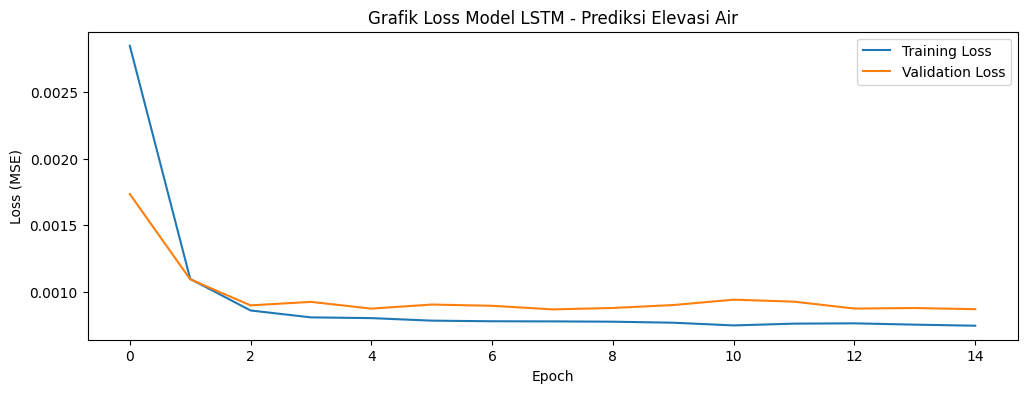

219/219 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step


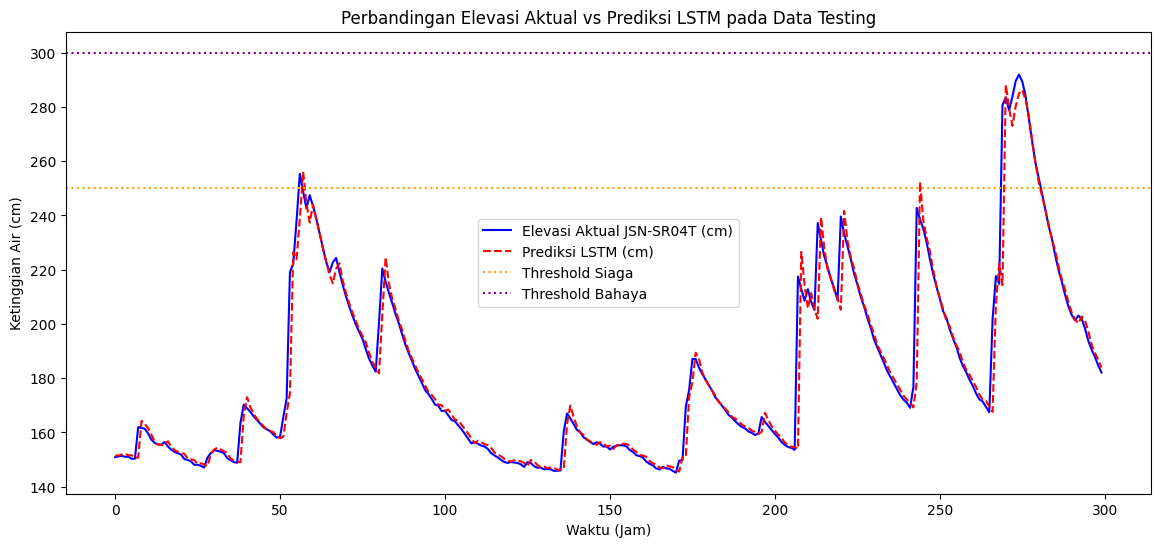


[SUKSES SEPENUHNYA] Training selesai! File model (.h5) dan scaler (.pkl) sudah siap diambil di Google Drive untuk diintegrasikan ke Web SCADA.


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import pickle
from datetime import datetime
from google.colab import drive, files
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# ==========================================
# 1. MOUNT GOOGLE DRIVE
# ==========================================
print("Menghubungkan ke Google Drive...")
drive.mount('/content/drive')

# Tentukan jalur penyimpanan di Google Drive Anda
drive_path = '/content/drive/My Drive/dataset_fusi_jsn_bmkg_2021_2026.csv'
model_save_path = '/content/drive/My Drive/model_lstm_banjir.h5'
scaler_save_path = '/content/drive/My Drive/scaler.pkl'

# ==========================================
# 2. TARIK SELURUH DATA HISTORIS (2021 - 2026) DARI OPEN-METEO API
# ==========================================
lat = "-6.365"
lon = "106.820"
start_date = "2021-01-01"
end_date = "2026-05-01"

url = f"https://archive-api.open-meteo.com/v1/archive?latitude={lat}&longitude={lon}&start_date={start_date}&end_date={end_date}&hourly=temperature_2m,relative_humidity_2m,precipitation,shortwave_radiation&timezone=Asia%2FJakarta"

print(f"\nSedang menarik seluruh data historis dari {start_date} sampai {end_date}...")
response = requests.get(url, timeout=60)
response.raise_for_status()
data = response.json().get("hourly", {})

# Konversi ke Pandas DataFrame
df = pd.DataFrame({
    "Waktu": data.get("time", []),
    "Suhu (°C)": data.get("temperature_2m", []),
    "Kelembapan (%)": data.get("relative_humidity_2m", []),
    "Curah Hujan (mm)": data.get("precipitation", []),
    "GHI (W/m²)": data.get("shortwave_radiation", [])
})

# ==========================================
# 3. GENERATE SENSOR FISIK JSN-SR04T (ELEVASI AIR)
# ==========================================
np.random.seed(42)
n = len(df)
rain = df['Curah Hujan (mm)'].values
elevation = np.zeros(n)
current_level = 150.0 # Baseline normal elevasi air sungai (cm)

for i in range(n):
    inflow = rain[i] * 6.5 + np.random.normal(0, 0.4)
    recession = (current_level - 140.0) * 0.06 if current_level > 140.0 else 0.0
    current_level = current_level + inflow - recession + np.random.normal(0, 0.15)
    current_level = np.clip(current_level, 100.0, 420.0)
    elevation[i] = round(current_level, 2)

df['Elevasi Air JSN-SR04T (cm)'] = elevation

# ==========================================
# 4. SIMPAN DATASET KE GOOGLE DRIVE
# ==========================================
df.to_csv(drive_path, index=False)
print(f"\n[SUKSES] Dataset tersimpan di: {drive_path}")
display(df.head())

# ==========================================
# 5. PREPROCESSING & SCALER UNTUK LSTM
# ==========================================
df['Waktu'] = pd.to_datetime(df['Waktu'])
df.set_index('Waktu', inplace=True)

target_column = 'Elevasi Air JSN-SR04T (cm)'
df = df.interpolate(method='linear').bfill().ffill()

data = df[[target_column]].values

# Normalisasi Min-Max Scaler ke rentang [0, 1]
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

# SIMPAN OBJEK SCALER KE GOOGLE DRIVE (PENTING UNTUK WEBSITE)
with open(scaler_save_path, 'wb') as f:
    pickle.dump(scaler, f)
print(f"[SUKSES] Objek Scaler tersimpan di: {scaler_save_path}")

# ==========================================
# 6. MEMBUAT SLIDING WINDOW (SEKUEN 24 JAM)
# ==========================================
def create_sequences(dataset, time_step=24):
    X, y = [], []
    for i in range(len(dataset) - time_step - 1):
        X.append(dataset[i:(i + time_step), 0])
        y.append(dataset[i + time_step, 0])
    return np.array(X), np.array(y)

time_step = 24
X, y = create_sequences(scaled_data, time_step)
X = X.reshape(X.shape[0], X.shape[1], 1)

# ==========================================
# 7. PEMBAGIAN DATA: TRAIN (70%), VAL (15%), TEST (15%)
# ==========================================
total_len = len(X)
train_end = int(total_len * 0.70)
val_end = int(total_len * 0.85)

X_train, y_train = X[:train_end], y[:train_end]
X_val, y_val = X[train_end:val_end], y[train_end:val_end]
X_test, y_test = X[val_end:], y[val_end:]

print(f"\nDistribusi Dataset Training & Testing:")
print(f"- Training (70%)   : {X_train.shape[0]} sekuen")
print(f"- Validation (15%) : {X_val.shape[0]} sekuen")
print(f"- Testing (15%)    : {X_test.shape[0]} sekuen")

# ==========================================
# 8. ARSITEKTUR MODEL LSTM
# ==========================================
model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(time_step, 1)),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(16),
    Dense(1)
])

model.compile(optimizer='adam', loss='mean_squared_error')
model.summary()

# ==========================================
# 9. TRAINING MODEL LSTM
# ==========================================
history = model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

# SIMPAN MODEL LSTM KE GOOGLE DRIVE (PENTING UNTUK WEBSITE)
model.save(model_save_path)
print(f"\n[SUKSES] Model LSTM berhasil disimpan di: {model_save_path}")

# ==========================================
# 10. VISUALISASI HASIL & EVALUASI
# ==========================================
plt.figure(figsize=(12, 4))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Grafik Loss Model LSTM - Prediksi Elevasi Air')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.show()

# Prediksi pada Data Test
test_predict = model.predict(X_test)
test_predict_inv = scaler.inverse_transform(test_predict)
y_test_inv = scaler.inverse_transform(y_test.reshape(-1, 1))

plt.figure(figsize=(14, 6))
plt.plot(y_test_inv[-300:], label='Elevasi Aktual JSN-SR04T (cm)', color='blue')
plt.plot(test_predict_inv[-300:], label='Prediksi LSTM (cm)', color='red', linestyle='--')
plt.axhline(y=250, color='orange', linestyle=':', label='Threshold Siaga')
plt.axhline(y=300, color='purple', linestyle=':', label='Threshold Bahaya')
plt.title('Perbandingan Elevasi Aktual vs Prediksi LSTM pada Data Testing')
plt.xlabel('Waktu (Jam)')
plt.ylabel('Ketinggian Air (cm)')
plt.legend()
plt.show()

print("\n[SUKSES SEPENUHNYA] Training selesai! File model (.h5) dan scaler (.pkl) sudah siap diambil di Google Drive untuk diintegrasikan ke Web SCADA.")